# 02b - Improvement round: toward >= 90% accuracy (honestly measured)

Goal: improve the ncRNA + clinical model (AD vs NC) **without** leaking information.

What changes vs notebook 02:
1. **Two ncRNA filters:** miRNAs detected in >= 80% (817) or >= 50% (1152) of training samples.
2. **Larger hyperparameter grids** for LogReg (elastic net), GradBoost and XGBoost.
3. **Ensembles:** averaged probabilities of LogReg + XGBoost (+ GradBoost).
4. **Decision threshold chosen inside each training fold** (never on the test fold):
   - `accuracy` rule: maximize accuracy (what the project target asks for)
   - `balanced` rule: maximize balanced accuracy (sensitivity + specificity)

Runs are produced by `src/run_improve.py` (cached in `results/models/02b_runs/`).
**Training split only. The held-out test set is still untouched.**

> Note on accuracy: 78% of these samples are AD, so a model that always says "AD" scores 78% accuracy.
> Accuracy is reported together with balanced accuracy, sensitivity, specificity and AUC.

In [1]:
import sys, json
sys.path.append("../src")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve

from utils import load_dataset, ROOT, FIGURES
from modeling import evaluate_with_threshold, metrics, bootstrap_auc_ci, bootstrap_auc_diff

RUNS = ROOT / "results" / "models" / "02b_runs"
TAB = ROOT / "results" / "tables"
FIG = FIGURES / "02b_improve"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def savefig(n): plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight")

_, clin = load_dataset("GSE120584_serum", split="train", diagnoses=["AD", "NC"])
y = (clin["diagnosis"] == "AD").astype(int)
print(f"AD {y.sum()}, NC {(1-y).sum()}  ->  'always AD' accuracy = {y.mean():.3f}")

runs = {f"{r['filter']}_{r['algo']}": r for r in (joblib.load(p) for p in sorted(RUNS.glob("*.joblib")))}
list(runs)

AD 816, NC 230  ->  'always AD' accuracy = 0.780


['det50_GradBoost',
 'det50_LogReg',
 'det50_XGBoost',
 'det80_GradBoost',
 'det80_LogReg',
 'det80_XGBoost']

## 1. Ensembles (built fold-by-fold from the same outer splits)

In [2]:
def ensemble(names):
    oof = runs[names[0]]["oof"].copy()
    oof["score"] = np.mean([runs[n]["oof"]["score"].astype(float) for n in names], axis=0)
    inner = {f: pd.concat([runs[n]["inner"][f] for n in names], axis=1).mean(axis=1)
             for f in runs[names[0]]["inner"]}
    return {"oof": oof, "inner": inner, "components": names}

models = {k: {"oof": v["oof"], "inner": v["inner"], "components": [k]} for k, v in runs.items()}
for filt in ["det80", "det50"]:
    a = [f"{filt}_LogReg", f"{filt}_XGBoost"]
    b = a + [f"{filt}_GradBoost"]
    if all(n in runs for n in b):
        models[f"{filt}_ENS(LogReg+XGB)"] = ensemble(a)
        models[f"{filt}_ENS(LogReg+XGB+GB)"] = ensemble(b)
list(models)

['det50_GradBoost',
 'det50_LogReg',
 'det50_XGBoost',
 'det80_GradBoost',
 'det80_LogReg',
 'det80_XGBoost',
 'det80_ENS(LogReg+XGB)',
 'det80_ENS(LogReg+XGB+GB)',
 'det50_ENS(LogReg+XGB)',
 'det50_ENS(LogReg+XGB+GB)']

## 2. Results with thresholds chosen on training folds

In [3]:
rows = []
for name, m in models.items():
    oof = m["oof"]
    lo, hi = bootstrap_auc_ci(y, oof["score"].astype(float), n=1000)
    r = {"model": name, "AUC": roc_auc_score(y, oof["score"].astype(float)), "AUC_95CI": f"{lo:.3f}-{hi:.3f}"}
    for rule in ["accuracy", "balanced"]:
        met, _ = evaluate_with_threshold(y, oof.assign(score=oof["score"].astype(float)), m["inner"], rule)
        for k in ["accuracy", "balanced_acc", "sensitivity", "specificity"]:
            r[f"{rule[:3]}_{k}"] = met[k]
    rows.append(r)
res = pd.DataFrame(rows).sort_values("AUC", ascending=False)
res.to_csv(TAB / "02b_improve_results.csv", index=False)
res.round(3)

,model,AUC,AUC_95CI,acc_accuracy,acc_balanced_acc,acc_sensitivity,acc_specificity,bal_accuracy,bal_balanced_acc,bal_sensitivity,bal_specificity
7,det80_ENS(LogReg+XGB+GB),0.915,0.890-0.937,0.889,0.790,0.967,0.613,0.819,0.822,0.817,0.826
6,det80_ENS(LogReg+XGB),0.913,0.887-0.935,0.896,0.807,0.966,0.648,0.838,0.834,0.842,0.826
5,det80_XGBoost,0.909,0.884-0.932,0.883,0.785,0.961,0.609,0.833,0.832,0.833,0.830
8,det50_ENS(LogReg+XGB),0.909,0.885-0.932,0.889,0.792,0.966,0.617,0.855,0.838,0.868,0.809
2,det50_XGBoost,0.909,0.883-0.930,0.886,0.785,0.966,0.604,0.840,0.829,0.849,0.809
9,det50_ENS(LogReg+XGB+GB),0.907,0.882-0.930,0.876,0.780,0.951,0.609,0.819,0.822,0.817,0.826
4,det80_LogReg,0.904,0.877-0.926,0.884,0.799,0.951,0.648,0.839,0.827,0.849,0.804
3,det80_GradBoost,0.898,0.873-0.922,0.874,0.782,0.946,0.617,0.818,0.821,0.816,0.826
1,det50_LogReg,0.896,0.870-0.920,0.878,0.787,0.949,0.626,0.834,0.825,0.841,0.809
0,det50_GradBoost,0.878,0.851-0.905,0.867,0.763,0.949,0.578,0.801,0.802,0.800,0.804


In [4]:
ref = pd.read_csv(TAB / "02_model_comparison.csv")
ref = ref[ref.feature_set == "C_ncrna+clinical"].set_index("algorithm")
print("Reference from notebook 02 (default grid, 817 miRNAs, threshold 0.5):")
print(ref[["AUC_mean", "sensitivity", "specificity", "balanced_acc"]].round(3).to_string())

Reference from notebook 02 (default grid, 817 miRNAs, threshold 0.5):
              AUC_mean  sensitivity  specificity  balanced_acc
algorithm                                                     
LogReg           0.900        0.853        0.813         0.833
RandomForest     0.858        0.967        0.422         0.694
SVM              0.870        0.946        0.643         0.795
KNN              0.830        0.984        0.283         0.633
GradBoost        0.899        0.947        0.604         0.776
XGBoost          0.907        0.955        0.661         0.808


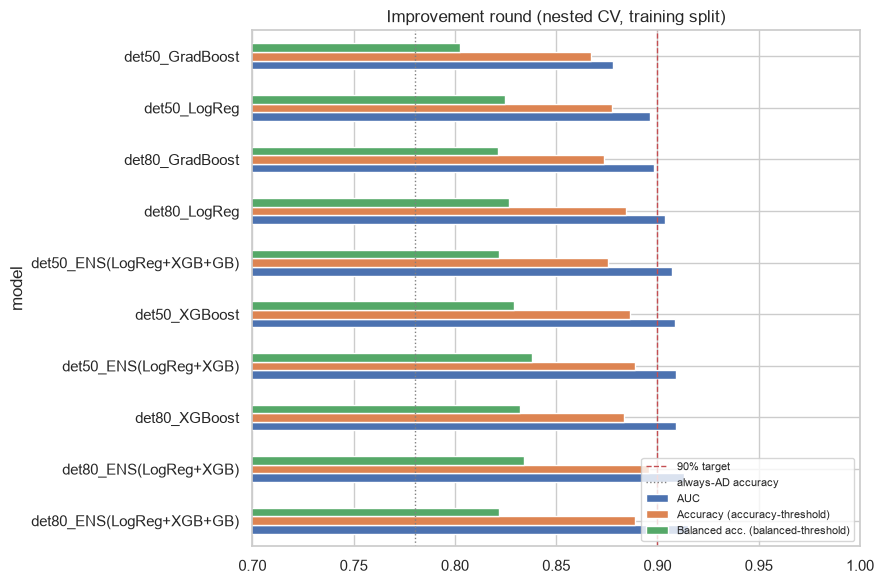

In [5]:
plot = res.set_index("model")[["AUC", "acc_accuracy", "bal_balanced_acc"]].rename(columns={
    "AUC": "AUC", "acc_accuracy": "Accuracy (accuracy-threshold)", "bal_balanced_acc": "Balanced acc. (balanced-threshold)"})
ax = plot.plot(kind="barh", figsize=(9, 6), xlim=(0.7, 1.0))
ax.axvline(0.90, c="r", ls="--", lw=1, label="90% target"); ax.axvline(y.mean(), c="gray", ls=":", lw=1, label="always-AD accuracy")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Improvement round (nested CV, training split)")
plt.tight_layout(); savefig("improve_summary"); plt.show()

## 3. Choose the final model

Rule: highest AUC (threshold-free, most robust); the decision threshold is then chosen on the training
data with the `accuracy` rule (project target), and balanced-threshold results are reported alongside.

Caveat: picking the best of ~10 configurations on the same CV folds is slightly optimistic.
The held-out test set (notebook 04) gives the unbiased final number.

In [6]:
best = res.iloc[0]
print(best.to_string())

base = models[best.model]
prev = joblib.load(ROOT / "results" / "models" / "02_nested_cv_results.joblib")[("C_ncrna+clinical", "XGBoost")]["oof"]
d, lo, hi, p = bootstrap_auc_diff(y, prev["score"].astype(float), base["oof"]["score"].astype(float), n=1000)
print(f"\nAUC change vs notebook-02 XGBoost: {d:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")

choice = {"model": best.model, "AUC_cv": round(float(best.AUC), 4),
          "accuracy_cv": round(float(best.acc_accuracy), 4), "balanced_acc_cv": round(float(best.bal_balanced_acc), 4),
          "threshold_rule": "accuracy (chosen on training data)",
          "components": {k: runs[k]["folds"]["best_params"].tolist() for k in base["components"]}}
json.dump(choice, open(ROOT / "results" / "models" / "02b_final_model_choice.json", "w"), indent=2, default=str)
print(json.dumps({k: v for k, v in choice.items() if k != "components"}, indent=2))

model               det80_ENS(LogReg+XGB+GB)
AUC                                 0.915287
AUC_95CI                         0.890-0.937
acc_accuracy                        0.889101
acc_balanced_acc                    0.789978
acc_sensitivity                     0.966912
acc_specificity                     0.613043
bal_accuracy                        0.819312
bal_balanced_acc                    0.821744
bal_sensitivity                     0.817402
bal_specificity                     0.826087



AUC change vs notebook-02 XGBoost: +0.006 (95% CI -0.004 to +0.015)
{
  "model": "det80_ENS(LogReg+XGB+GB)",
  "AUC_cv": 0.9153,
  "accuracy_cv": 0.8891,
  "balanced_acc_cv": 0.8217,
  "threshold_rule": "accuracy (chosen on training data)"
}


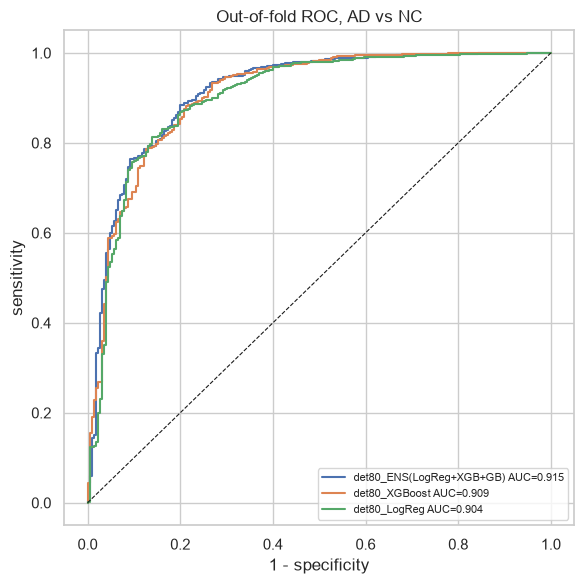

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in [best.model, "det80_XGBoost", "det80_LogReg"]:
    if name in models:
        s = models[name]["oof"]["score"].astype(float)
        fpr, tpr, _ = roc_curve(y, s); ax.plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(y, s):.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("1 - specificity"); ax.set_ylabel("sensitivity")
ax.legend(fontsize=8); ax.set_title("Out-of-fold ROC, AD vs NC"); plt.tight_layout(); savefig("roc"); plt.show()

## 4. Findings to record (fill in)
- Best model and AUC:
- Accuracy (accuracy-threshold) and how far above the 78% "always AD" level:
- Balanced accuracy / sensitivity / specificity:
- Did the 50% filter (more miRNAs, incl. classic AD ones) help?
- Did the ensemble help?